# TDCS: fresh two-target sequence training

## tl;dr

**Target: at least 0.6 pooled native-row two-target mAP. Not achieved or
promised by this notebook before training finishes.** The preserved best
StartHesitation/Walking development reference is 0.1963.

This is actual from-scratch training, not another adjustment of old blend
weights. Two different three-layer bidirectional GRU models learn only
StartHesitation and Walking. Turn is absent from the heads and loss;
Turn-only periods remain negative examples. Existing TDCS and DeFOG results
are not overwritten and no competition submission is made.

On Kaggle, **Run All trains the full experiment on GPU T4 x2**. Locally,
Run All defaults to a synthetic CPU wiring test, clearly flagged as not a
TDCS performance result. The GPU run's results are pending until it completes.

## Context & Methods

- Fresh two-output BiGRU with BCE, and gated convolution + BiGRU with BCE
  plus a modest pairwise ranking loss. Equal-weight neural ensemble is fixed.
- 24 fixed epochs, 144 batches per epoch, batch size 32. AdamW with a 5%
  warmup and linear learning-rate decay; gradient clipping and EMA weights.
- 50% event-centered crops balanced by target and subject, 25% negative
  centers, 25% natural centers. No extra inverse-frequency positive weights:
  this avoids applying two imbalance corrections simultaneously.
- Robust per-record scaling of axes, prior/next differences and cumulative
  signals, plus three recording-progress features. Mild amplitude/axis augmentation.
- Train on 1000 native rows; infer on 5000-row windows with overlapping
  center stitching and explicit native-row coverage checks.
- Five frozen subject-held-out folds, 815 recordings, 61 subjects; exclude
  public-example subject `4dc2f8`. All native rows are scored for both targets.
- No outer validation labels for early stopping or checkpoint selection.
  Final fixed-epoch EMA weights are used; outer labels are used for scoring.

These are adaptations, not an exact reproduction or a claimed winning model.
References: [second-place short-train / long-inference GRU recipe](https://www.kaggle.com/competitions/tlvmc-parkinsons-freezing-gait-prediction/writeups/waiwai-2nd-place-solution),
[fifth-place gated WaveNet/GRU approach](https://www.kaggle.com/c/tlvmc-parkinsons-freezing-gait-prediction/discussion/416298),
and [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html).

### Key Assumptions

- The 0.6 target is **two-target mAP**, with each class AP also reported.
  It is not directly comparable to old three-class or combined-domain scores.
- Keep negatives and subject splits. Do not produce a higher-looking number
  by filtering easy/positive windows or changing the evaluation population.
- Per-record normalization and bidirectional context assume offline inference.
- The scores are independent sigmoids, not mutually exclusive confidences.
  Event oversampling means they are not yet calibrated event probabilities.
- Architecture selection has reused these development folds; results remain
  exploratory rather than independent final-generalization estimates.
- This experiment uses TDCS data only. DeFOG is neither trained nor modified.

### Choose full training or local synthetic smoke mode

In [1]:
import contextlib
import hashlib
import io
import json
import os
import sys
import traceback
import types
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image

IS_KAGGLE = Path('/kaggle/working').exists()
RUN_FULL_TRAINING = os.environ.get('TDCS_RUN_FULL', '1' if IS_KAGGLE else '0') == '1'
PROJECT_ROOT = Path('D:/Dissertation') if Path('D:/Dissertation/data').exists() else Path.cwd()
WORK_ROOT = Path('/kaggle/working/tdcs_two_target_neural') if IS_KAGGLE else PROJECT_ROOT / 'tmp/tdcs_neural_notebook_smoke'
WORK_ROOT.mkdir(parents=True, exist_ok=True)
status = {'stage': 'python_imports_ready', 'full_training': RUN_FULL_TRAINING,
          'torch': str(torch.__version__), 'cuda_available': torch.cuda.is_available(),
          'gpu_count': torch.cuda.device_count()}
(WORK_ROOT / 'startup_status.json').write_text(json.dumps(status, indent=2))
if RUN_FULL_TRAINING and not torch.cuda.is_available():
    raise RuntimeError('Full training requires a GPU. Select GPU T4 x2; no silent smoke fallback on Kaggle.')
print(status)
print('GPU full training' if RUN_FULL_TRAINING else 'Synthetic CPU wiring test ONLY; not a TDCS score')

{'stage': 'python_imports_ready', 'full_training': False, 'torch': '2.8.0+cpu', 'cuda_available': False, 'gpu_count': 0}
Synthetic CPU wiring test ONLY; not a TDCS score


### Load the embedded trainer

The full source and immutable subject-fold mapping are embedded so Kaggle
does not need a separate project-code input or internet access. Expand this
cell to inspect the trainer; the matching readable source is
`scripts/tdcs_two_target_neural.py` in the local project.

In [2]:
SOURCE_SHA256 = 'f8db1ad2934adf9c55cf466e36fa9c5e512b62acf2590f5808a4c765eaff5064'
TRAINER_SOURCE = '"""Fresh two-output TDCS sequence models, with frozen subject-held-out evaluation.\n\nNo Turn head, no prior neural checkpoint, no leaderboard/submission call. Models\nuse event/subject-balanced training and longer context only at inference. Fixed\nepochs and EMA checkpoints avoid selecting epochs on outer evaluation labels.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport copy\nimport hashlib\nimport json\nimport math\nimport os\nimport random\nimport sys\nimport time\nfrom dataclasses import asdict, dataclass, replace\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom sklearn.metrics import average_precision_score\n\nfrom tdcs_multiscale_signal_experiment import AXES, FROZEN_SUBJECT_FOLDS\n\nTARGETS = (\'StartHesitation\', \'Walking\')\nROOT = Path(__file__).resolve().parents[1]\n\n\n@dataclass(frozen=True)\nclass Config:\n    name: str = \'two_target_sequence_v1\'\n    targets: tuple = TARGETS\n    variants: tuple = (\'bigru_bce\', \'gated_bigru_rank\')\n    folds: tuple = (0, 1, 2, 3, 4)\n    epochs: int = 24\n    steps_per_epoch: int = 144\n    batch_size: int = 32\n    train_length: int = 1000\n    inference_length: int = 5000\n    inference_batch: int = 4\n    hidden: int = 128\n    gru_layers: int = 3\n    width: int = 64\n    dropout: float = 0.15\n    learning_rate: float = 0.001\n    weight_decay: float = 0.0001\n    event_fraction: float = 0.5\n    negative_fraction: float = 0.25\n    rank_weight: float = 0.1\n    ema_decay: float = 0.995\n    seed: int = 731\n    goal_two_target_map: float = 0.6\n\n\nCFG = Config()\n\n\ndef write_json(path: Path, payload: dict):\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(\'.tmp.json\')\n    temporary.write_text(json.dumps(payload, indent=2, default=str), encoding=\'utf-8\')\n    os.replace(temporary, path)\n\n\ndef locate_data():\n    candidates = [ROOT / \'data/metadata\', Path.cwd() / \'data/metadata\']\n    mount = Path(\'/kaggle/input\')\n    if mount.exists():\n        candidates = [p.parent for p in sorted(mount.rglob(\'tdcsfog_metadata.csv\'))] + candidates\n    for metadata_root in candidates:\n        metadata_path = metadata_root / \'tdcsfog_metadata.csv\'\n        for raw in [metadata_root / \'train/tdcsfog\', metadata_root.parent / \'raw/train/tdcsfog\']:\n            if metadata_path.exists() and raw.is_dir():\n                return raw, metadata_path\n    raise FileNotFoundError(\'Attach the competition data: need tdcsfog_metadata.csv and train/tdcsfog\')\n\n\ndef build_manifest(raw_root: Path, metadata_path: Path):\n    metadata = pd.read_csv(metadata_path, dtype={\'Id\': str, \'Subject\': str})\n    if metadata.Id.duplicated().any():\n        raise ValueError(\'Duplicate recording metadata\')\n    subject_by_id = metadata.set_index(\'Id\').Subject.to_dict()\n    rows = []\n    for path in sorted(raw_root.glob(\'*.csv\')):\n        subject = subject_by_id.get(path.stem)\n        if subject == \'4dc2f8\':\n            continue\n        if subject not in FROZEN_SUBJECT_FOLDS:\n            raise ValueError(f\'Unexpected/missing subject for recording {path.stem}\')\n        rows.append({\'recording_id\': path.stem, \'subject\': subject,\n                     \'fold\': FROZEN_SUBJECT_FOLDS[subject], \'path\': str(path), \'source_bytes\': path.stat().st_size})\n    manifest = pd.DataFrame(rows)\n    if len(manifest) != 815 or manifest.subject.nunique() != 61:\n        raise ValueError(\'Frozen development population must be 815 recordings / 61 subjects\')\n    if manifest.groupby(\'subject\').fold.nunique().max() != 1:\n        raise ValueError(\'Subject leakage between folds\')\n    return manifest\n\n\ndef sensor_features(raw: np.ndarray):\n    raw = np.asarray(raw, np.float32)\n    if raw.ndim != 2 or raw.shape[1] != 3 or len(raw) < 2 or not np.isfinite(raw).all():\n        raise ValueError(\'Need a finite recording with at least two rows and three accelerometer axes\')\n    lag = np.vstack([np.zeros((1, 3), np.float32), np.diff(raw, axis=0)])\n    lead = np.vstack([np.diff(raw, axis=0), np.zeros((1, 3), np.float32)])\n    integrated = np.cumsum(raw - np.median(raw, axis=0, keepdims=True), axis=0, dtype=np.float64).astype(np.float32)\n    values = np.concatenate([raw, lag, lead, integrated], axis=1)\n    median = np.median(values, axis=0)\n    q25, q75 = np.quantile(values, [0.25, 0.75], axis=0)\n    values = (values - median) / np.maximum(q75 - q25, 1e-4)\n    position = np.arange(len(raw), dtype=np.float64)\n    seconds = position / 128.0\n    timing = np.column_stack([position / max(len(raw) - 1, 1), np.log1p(seconds) / 8,\n                              np.log1p((len(raw) - 1 - position) / 128.0) / 8])\n    features = np.column_stack([np.clip(values, -20, 20), timing]).astype(np.float32)\n    if not np.isfinite(features).all():\n        raise ValueError(\'Invalid robust features\')\n    return features\n\n\ndef event_centers(labels: np.ndarray):\n    labels = np.asarray(labels, bool)\n    starts = np.flatnonzero(labels & ~np.r_[False, labels[:-1]])\n    stops = np.flatnonzero(labels & ~np.r_[labels[1:], False]) + 1\n    return ((starts + stops - 1) // 2).astype(np.int64)\n\n\ndef prepare_records(manifest: pd.DataFrame):\n    records = []\n    for index, row in enumerate(manifest.itertuples(index=False)):\n        frame = pd.read_csv(row.path, usecols=[*AXES, *TARGETS])\n        y = frame.loc[:, list(TARGETS)].to_numpy()\n        if not np.isin(y, [0, 1]).all():\n            raise ValueError(\'Targets must be binary\')\n        x = sensor_features(frame.loc[:, list(AXES)].to_numpy(np.float32))\n        negative = np.flatnonzero(y.sum(axis=1) == 0)\n        negative = negative[::max(1, len(negative) // 2000)]\n        records.append({\'recording_id\': row.recording_id, \'subject\': row.subject, \'fold\': row.fold,\n                        \'x\': x, \'y\': y.astype(np.float32), \'negative\': negative,\n                        \'centers\': [event_centers(y[:, i]) for i in range(2)]})\n        if (index + 1) % 100 == 0:\n            print(f\'Prepared sensor records: {index + 1}/{len(manifest)}\', flush=True)\n    if sum(len(r[\'y\']) for r in records) != 6959762:\n        raise ValueError(\'Native population changed\')\n    return records\n\n\ndef padded_window(x, y, start, length):\n    indices = np.arange(start, start + length)\n    valid = (indices >= 0) & (indices < len(x))\n    window = x[np.clip(indices, 0, len(x) - 1)].copy()\n    labels = np.zeros((length, 2), np.float32)\n    labels[valid] = y[indices[valid]]\n    return window, labels, np.repeat(valid[:, None], 2, axis=1).astype(np.float32)\n\n\nclass EventSampler:\n    def __init__(self, records, held_out_fold, cfg):\n        self.cfg = cfg\n        self.records = [r for r in records if r[\'fold\'] != held_out_fold]\n        self.held_out_fold = held_out_fold\n        if not self.records or any(r[\'fold\'] == held_out_fold for r in self.records):\n            raise ValueError(\'Training records cross the held-out fold\')\n        self.subjects = {}\n        self.positive = [{}, {}]\n        self.negative = {}\n        for record in self.records:\n            subject = record[\'subject\']\n            self.subjects.setdefault(subject, []).append(record)\n            if len(record[\'negative\']):\n                self.negative.setdefault(subject, []).append(record)\n            for target in range(2):\n                if len(record[\'centers\'][target]):\n                    self.positive[target].setdefault(subject, []).append(record)\n        self.available_targets = [t for t in range(2) if self.positive[t]]\n        if len(self.available_targets) != 2:\n            raise ValueError(\'Both targets require training events\')\n\n    @staticmethod\n    def choose_record(pool, rng):\n        subjects = sorted(pool)\n        subject = subjects[int(rng.integers(len(subjects)))]\n        choices = pool[subject]\n        return choices[int(rng.integers(len(choices)))]\n\n    def plan(self, rng):\n        draw = rng.random()\n        if draw < self.cfg.event_fraction:\n            target = int(rng.choice(self.available_targets))\n            record = self.choose_record(self.positive[target], rng)\n            center = int(rng.choice(record[\'centers\'][target]))\n            center += int(rng.integers(-self.cfg.train_length // 5, self.cfg.train_length // 5 + 1))\n        elif draw < self.cfg.event_fraction + self.cfg.negative_fraction and self.negative:\n            record = self.choose_record(self.negative, rng)\n            center = int(rng.choice(record[\'negative\']))\n        else:\n            record = self.choose_record(self.subjects, rng)\n            center = int(rng.integers(len(record[\'x\'])))\n        center = int(np.clip(center, 0, len(record[\'x\']) - 1))\n        return record, center - self.cfg.train_length // 2\n\n    def batch(self, rng):\n        x_parts, y_parts, masks = [], [], []\n        for _ in range(self.cfg.batch_size):\n            record, start = self.plan(rng)\n            x, y, mask = padded_window(record[\'x\'], record[\'y\'], start, self.cfg.train_length)\n            # Mild amplitude/axis perturbation, applied coherently to all four 3-axis blocks.\n            gains = rng.uniform(0.95, 1.05, 3).astype(np.float32)\n            x[:, :12] *= np.tile(gains, 4)\n            theta = float(rng.uniform(-0.10, 0.10))\n            rotation = np.array([[1, 0, 0], [0, np.cos(theta), -np.sin(theta)],\n                                 [0, np.sin(theta), np.cos(theta)]], np.float32)\n            for begin in range(0, 12, 3):\n                x[:, begin:begin + 3] = x[:, begin:begin + 3] @ rotation.T\n            x_parts.append(x)\n            y_parts.append(y)\n            masks.append(mask)\n        return tuple(torch.from_numpy(np.stack(parts)) for parts in [x_parts, y_parts, masks])\n\n\nclass GatedBlock(nn.Module):\n    def __init__(self, width, dilation):\n        super().__init__()\n        self.filter = nn.Conv1d(width, width, 3, padding=dilation, dilation=dilation)\n        self.gate = nn.Conv1d(width, width, 3, padding=dilation, dilation=dilation)\n        self.output = nn.Conv1d(width, width, 1)\n        self.norm = nn.GroupNorm(8, width)\n\n    def forward(self, x):\n        h = torch.tanh(self.filter(x)) * torch.sigmoid(self.gate(x))\n        return x + self.output(self.norm(h))\n\n\nclass TwoTargetGRU(nn.Module):\n    def __init__(self, cfg=CFG, variant=\'bigru_bce\'):\n        super().__init__()\n        if variant not in (\'bigru_bce\', \'gated_bigru_rank\'):\n            raise ValueError(\'Unknown neural variant\')\n        self.input = nn.Sequential(nn.Linear(15, cfg.width), nn.LayerNorm(cfg.width), nn.GELU())\n        self.gated = nn.Sequential(*[GatedBlock(cfg.width, d) for d in (1, 2, 4, 8)]) if variant.startswith(\'gated\') else None\n        self.gru = nn.GRU(cfg.width, cfg.hidden, num_layers=cfg.gru_layers,\n                          dropout=cfg.dropout if cfg.gru_layers > 1 else 0,\n                          batch_first=True, bidirectional=True)\n        self.head = nn.Sequential(nn.Linear(2 * cfg.hidden, 128), nn.LayerNorm(128), nn.GELU(),\n                                  nn.Dropout(cfg.dropout), nn.Linear(128, 2))\n\n    def forward(self, x):\n        h = self.input(x)\n        if self.gated is not None:\n            h = self.gated(h.transpose(1, 2)).transpose(1, 2)\n        h, _ = self.gru(h.contiguous())\n        return self.head(h)\n\n\ndef sequence_loss(logits, labels, mask, rank_weight=0.0):\n    # Sampling already increases event frequency: do NOT also apply inverse-frequency positive weights.\n    bce = (F.binary_cross_entropy_with_logits(logits.float(), labels.float(), reduction=\'none\') * mask).sum()\n    loss = bce / mask.sum().clamp_min(1)\n    rank_terms = []\n    if rank_weight:\n        for target in range(2):\n            valid = mask[..., target] > 0\n            pos = logits[..., target][valid & (labels[..., target] > 0.5)].float()\n            neg = logits[..., target][valid & (labels[..., target] < 0.5)].float()\n            if pos.numel() and neg.numel():\n                pos = pos[torch.randperm(len(pos), device=pos.device)[:192]]\n                # Hard negatives are selected from this TRAINING batch, never from outer OOF labels.\n                neg = torch.topk(neg, min(192, len(neg))).values\n                rank_terms.append(F.softplus(neg[None, :] - pos[:, None]).mean())\n    if rank_terms:\n        loss = loss + rank_weight * torch.stack(rank_terms).mean()\n    return loss\n\n\ndef core_model(model):\n    return model.module if isinstance(model, nn.DataParallel) else model\n\n\ndef learning_rate_multiplier(step, total_steps):\n    warmup = max(1, int(total_steps * 0.05))\n    if step < warmup:\n        return max(0.001, (step + 1) / warmup)\n    return max(0.02, (total_steps - step) / max(total_steps - warmup, 1))\n\n\ndef train_model(records, fold, variant, cfg, run_dir, device, fingerprint):\n    fold_dir = run_dir / variant / f\'fold_{fold}\'\n    fold_dir.mkdir(parents=True, exist_ok=True)\n    final_path = fold_dir / \'final_ema.pt\'\n    seed = cfg.seed + 1009 * fold + (1 if variant.startswith(\'gated\') else 0)\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    network = TwoTargetGRU(cfg, variant).to(device)\n    if final_path.exists():\n        checkpoint = torch.load(final_path, map_location=device, weights_only=False)\n        if checkpoint[\'fingerprint\'] != fingerprint:\n            raise ValueError(\'Cannot reuse a checkpoint from another configuration\')\n        network.load_state_dict(checkpoint[\'model\'])\n        print(f\'Reusing completed {variant} fold {fold}\', flush=True)\n        return network\n    sampler = EventSampler(records, fold, cfg)\n    training_subjects = sorted(sampler.subjects)\n    held_out_subjects = sorted({r[\'subject\'] for r in records if r[\'fold\'] == fold})\n    if set(training_subjects) & set(held_out_subjects):\n        raise ValueError(\'Outer subject leakage\')\n    write_json(fold_dir / \'training_receipt.json\', {\'targets\': TARGETS, \'training_subjects\': training_subjects,\n        \'held_out_subjects\': held_out_subjects, \'outer_labels_used_for_checkpoint_selection\': False,\n        \'event_fraction\': cfg.event_fraction, \'negative_fraction\': cfg.negative_fraction,\n        \'positive_class_weights\': [1, 1], \'fixed_epochs\': cfg.epochs, \'seed\': seed})\n    ema = copy.deepcopy(network).eval()\n    ema.requires_grad_(False)\n    optimizer = torch.optim.AdamW(network.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)\n    total_steps = cfg.epochs * cfg.steps_per_epoch\n    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: learning_rate_multiplier(step, total_steps))\n    use_amp = device.type == \'cuda\'\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=use_amp)\n    start_epoch = 0\n    rng = np.random.default_rng(seed)\n    resume_path = fold_dir / \'resume.pt\'\n    if resume_path.exists():\n        saved = torch.load(resume_path, map_location=device, weights_only=False)\n        if saved[\'fingerprint\'] != fingerprint:\n            raise ValueError(\'Stale training resume state\')\n        network.load_state_dict(saved[\'model\'])\n        ema.load_state_dict(saved[\'ema\'])\n        optimizer.load_state_dict(saved[\'optimizer\'])\n        scheduler.load_state_dict(saved[\'scheduler\'])\n        scaler.load_state_dict(saved[\'scaler\'])\n        rng.bit_generator.state = saved[\'numpy_rng\']\n        torch.set_rng_state(saved[\'torch_rng\'].cpu())\n        if use_amp and saved[\'cuda_rng\'] is not None:\n            torch.cuda.set_rng_state_all([state.cpu() for state in saved[\'cuda_rng\']])\n        start_epoch = saved[\'next_epoch\']\n    if use_amp and torch.cuda.device_count() > 1:\n        network = nn.DataParallel(network)\n    history = []\n    history_path = fold_dir / \'training_log.csv\'\n    if history_path.exists():\n        history = pd.read_csv(history_path).to_dict(\'records\')\n    for epoch in range(start_epoch, cfg.epochs):\n        network.train()\n        started = time.monotonic()\n        losses, event_rows, valid_rows = [], np.zeros(2, np.float64), np.zeros(2, np.float64)\n        print(f\'{variant} fold {fold} epoch {epoch + 1}/{cfg.epochs}: training\', flush=True)\n        for step in range(cfg.steps_per_epoch):\n            x, y, mask = sampler.batch(rng)\n            event_rows += (y.numpy() * mask.numpy()).sum(axis=(0, 1))\n            valid_rows += mask.numpy().sum(axis=(0, 1))\n            if use_amp:\n                x, y, mask = [v.pin_memory().to(device, non_blocking=True) for v in (x, y, mask)]\n            else:\n                x, y, mask = [v.to(device) for v in (x, y, mask)]\n            optimizer.zero_grad(set_to_none=True)\n            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):\n                logits = network(x)\n                loss = sequence_loss(logits, y, mask, cfg.rank_weight if variant.startswith(\'gated\') else 0)\n            if not torch.isfinite(loss):\n                raise FloatingPointError(\'Non-finite training loss\')\n            scaler.scale(loss).backward()\n            scaler.unscale_(optimizer)\n            nn.utils.clip_grad_norm_(network.parameters(), 2.0)\n            scaler.step(optimizer)\n            scaler.update()\n            scheduler.step()\n            with torch.no_grad():\n                for destination, source in zip(ema.parameters(), core_model(network).parameters()):\n                    destination.lerp_(source.detach(), 1 - cfg.ema_decay)\n            losses.append(float(loss.detach().cpu()))\n        history.append({\'epoch\': epoch + 1, \'loss\': float(np.mean(losses)),\n                        \'StartHesitation_sampled_fraction\': float(event_rows[0] / valid_rows[0]),\n                        \'Walking_sampled_fraction\': float(event_rows[1] / valid_rows[1]),\n                        \'learning_rate\': scheduler.get_last_lr()[0], \'seconds\': time.monotonic() - started})\n        pd.DataFrame(history).to_csv(history_path, index=False)\n        state = {\'fingerprint\': fingerprint, \'model\': core_model(network).state_dict(), \'ema\': ema.state_dict(),\n                 \'optimizer\': optimizer.state_dict(), \'scheduler\': scheduler.state_dict(), \'scaler\': scaler.state_dict(),\n                 \'next_epoch\': epoch + 1, \'numpy_rng\': rng.bit_generator.state, \'torch_rng\': torch.get_rng_state(),\n                 \'cuda_rng\': torch.cuda.get_rng_state_all() if use_amp else None}\n        temporary = fold_dir / \'resume.tmp.pt\'\n        torch.save(state, temporary)\n        os.replace(temporary, resume_path)\n        write_json(run_dir / \'progress.json\', {\'stage\': \'training\', \'variant\': variant, \'fold\': fold,\n                   \'epoch_completed\': epoch + 1, \'epochs\': cfg.epochs, \'latest_training_loss\': history[-1][\'loss\']})\n        print(f\'{variant} fold {fold}: epoch {epoch + 1}, loss {history[-1]["loss"]:.5f}, {history[-1]["seconds"]:.1f}s\', flush=True)\n    torch.save({\'fingerprint\': fingerprint, \'model\': ema.state_dict(), \'targets\': TARGETS}, final_path)\n    return ema\n\n\ndef inference_starts(n, length):\n    if n <= length:\n        return [0]\n    starts = list(range(0, n - length + 1, max(1, length // 2)))\n    if starts[-1] != n - length:\n        starts.append(n - length)\n    return starts\n\n\ndef inference_weight(length, first, last):\n    weight = np.zeros(length, np.float32)\n    quarter = length // 4\n    weight[quarter:length - quarter] = 1\n    if first:\n        weight[:quarter] = 1\n    if last:\n        weight[length - quarter:] = 1\n    return weight\n\n\ndef predict_record(model, features, cfg, device):\n    n, length = len(features), cfg.inference_length\n    starts = inference_starts(n, length)\n    total = np.zeros((n, 2), np.float32)\n    denominator = np.zeros(n, np.float32)\n    model.eval()\n    with torch.inference_mode():\n        for begin in range(0, len(starts), cfg.inference_batch):\n            selected = starts[begin:begin + cfg.inference_batch]\n            windows = [features[np.clip(np.arange(start, start + length), 0, n - 1)] for start in selected]\n            x = torch.from_numpy(np.stack(windows)).to(device)\n            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == \'cuda\'):\n                p = torch.sigmoid(model(x).float()).cpu().numpy()\n            for i, start in enumerate(selected):\n                count = min(length, n - start)\n                weights = inference_weight(length, start == 0, start + length >= n)[:count]\n                total[start:start + count] += p[i, :count] * weights[:, None]\n                denominator[start:start + count] += weights\n    if (denominator <= 0).any():\n        raise ValueError(\'Inference windows left native rows uncovered\')\n    prediction = total / denominator[:, None]\n    if not np.isfinite(prediction).all():\n        raise ValueError(\'Non-finite prediction\')\n    return np.clip(prediction, 1e-6, 1 - 1e-6)\n\n\ndef average_precision(y, p):\n    result = {target: float(average_precision_score(y[:, i], p[:, i])) for i, target in enumerate(TARGETS)}\n    result[\'two_target_mAP\'] = float(np.mean(list(result.values())))\n    return result\n\n\ndef run_experiment(cfg=CFG, output_root=None, synthetic_records=None):\n    torch.set_num_threads(4)\n    torch.backends.cudnn.benchmark = True\n    device = torch.device(\'cuda\' if torch.cuda.is_available() else \'cpu\')\n    if synthetic_records is None and device.type != \'cuda\':\n        raise RuntimeError(\'Full sequence training requires a GPU; run the smoke mode locally instead\')\n    if output_root is None:\n        output_root = Path(\'/kaggle/working/tdcs_two_target_neural\') if Path(\'/kaggle/working\').exists() else ROOT / \'results/tdcs_two_target_neural\'\n    output_root = Path(output_root)\n    if synthetic_records is None:\n        raw_root, metadata_path = locate_data()\n        manifest = build_manifest(raw_root, metadata_path)\n        source_population = manifest[[\'recording_id\', \'subject\', \'fold\', \'source_bytes\']].to_csv(index=False)\n        metadata_sha = hashlib.sha256(metadata_path.read_bytes()).hexdigest()\n    else:\n        manifest = pd.DataFrame([{key: record[key] for key in [\'recording_id\', \'subject\', \'fold\']} for record in synthetic_records])\n        source_population = manifest.to_csv(index=False)\n        metadata_sha = \'synthetic smoke only\'\n    source_sha = globals().get(\'SOURCE_SHA256\') or hashlib.sha256(Path(__file__).read_bytes()).hexdigest()\n    config = {\'configuration\': asdict(cfg), \'source_sha256\': source_sha,\n              \'runtime_versions\': {\'torch\': str(torch.__version__), \'numpy\': np.__version__, \'pandas\': pd.__version__},\n              \'frozen_fold_sha256\': hashlib.sha256(json.dumps(FROZEN_SUBJECT_FOLDS, sort_keys=True).encode()).hexdigest(),\n              \'metadata_sha256\': metadata_sha, \'population_sha256\': hashlib.sha256(source_population.encode()).hexdigest(),\n              \'validation\': \'frozen outer subject folds; all native rows; no outer-label checkpoint selection\',\n              \'confidence\': \'independent sigmoid scores; event oversampling means not calibrated probability\',\n              \'leaderboard_scoring_used\': False, \'competition_submission_created\': False,\n              \'previous_two_target_reference\': 0.19629988455476777, \'goal_is_measured_not_guaranteed\': 0.6,\n              \'smoke_only\': synthetic_records is not None}\n    fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:20]\n    run_dir = output_root / fingerprint\n    run_dir.mkdir(parents=True, exist_ok=True)\n    write_json(run_dir / \'configuration.json\', config)\n    manifest.to_csv(run_dir / \'frozen_tdcs_manifest.csv\', index=False)\n    write_json(output_root / \'latest_run.json\', {\'run_dir\': str(run_dir), \'status\': \'running\'})\n    print(f\'Fresh TDCS neural run: {run_dir}; torch {torch.__version__}; {device}; GPUs {torch.cuda.device_count()}\', flush=True)\n    records = prepare_records(manifest) if synthetic_records is None else synthetic_records\n    model_metrics = []\n    for variant in cfg.variants:\n        for fold in cfg.folds:\n            model = train_model(records, fold, variant, cfg, run_dir, device, fingerprint)\n            oof_dir = run_dir / variant / \'oof\'\n            oof_dir.mkdir(parents=True, exist_ok=True)\n            ys, ps = [], []\n            for record in records:\n                if record[\'fold\'] != fold:\n                    continue\n                path = oof_dir / f\'{record["recording_id"]}.npz\'\n                if path.exists():\n                    with np.load(path, allow_pickle=False) as payload:\n                        p = payload[\'prediction\']\n                else:\n                    p = predict_record(model, record[\'x\'], cfg, device)\n                    np.savez_compressed(path, prediction=p, targets=np.asarray(TARGETS))\n                if p.shape != record[\'y\'].shape or not np.isfinite(p).all():\n                    raise ValueError(\'Native-row OOF alignment failure\')\n                ys.append(record[\'y\'])\n                ps.append(p)\n            score = {\'variant\': variant, \'fold\': fold, **average_precision(np.concatenate(ys), np.concatenate(ps))}\n            model_metrics.append(score)\n            pd.DataFrame(model_metrics).to_csv(run_dir / \'fold_metrics.csv\', index=False)\n            write_json(run_dir / \'progress.json\', {\'stage\': \'fold_scored\', **score})\n            print(json.dumps(score), flush=True)\n            del model\n            if device.type == \'cuda\':\n                torch.cuda.empty_cache()\n    y = np.concatenate([record[\'y\'] for record in records if record[\'fold\'] in cfg.folds])\n    predictions = {}\n    for variant in cfg.variants:\n        parts = []\n        for record in records:\n            if record[\'fold\'] in cfg.folds:\n                with np.load(run_dir / variant / \'oof\' / f\'{record["recording_id"]}.npz\', allow_pickle=False) as payload:\n                    parts.append(payload[\'prediction\'])\n        predictions[variant] = np.concatenate(parts)\n    predictions[\'neural_equal_ensemble\'] = sum(predictions.values()) / len(predictions)\n    metrics = pd.DataFrame([{\'method\': method, **average_precision(y, p)} for method, p in predictions.items()])\n    metrics.to_csv(run_dir / \'candidate_metrics.csv\', index=False)\n    selected = metrics.sort_values(\'two_target_mAP\', ascending=False).iloc[0]\n    selected_dir = run_dir / \'selected_candidate\'\n    (selected_dir / \'oof\').mkdir(parents=True, exist_ok=True)\n    manifest.to_csv(selected_dir / \'frozen_tdcs_manifest.csv\', index=False)\n    pd.DataFrame([selected]).to_csv(selected_dir / \'native_oof_metrics.csv\', index=False)\n    offset = 0\n    for record in records:\n        if record[\'fold\'] not in cfg.folds:\n            continue\n        n = len(record[\'y\'])\n        np.savez_compressed(selected_dir / \'oof\' / f\'{record["recording_id"]}.npz\',\n                            prediction=predictions[str(selected.method)][offset:offset + n], targets=np.asarray(TARGETS))\n        offset += n\n    decision = {\'run_dir\': str(run_dir), \'selected_candidate_dir\': str(selected_dir), \'status\': \'complete\',\n                \'selected_method\': str(selected.method), \'two_target_mAP\': float(selected.two_target_mAP),\n                \'class_average_precision\': {target: float(selected[target]) for target in TARGETS},\n                \'reference_two_target_map\': 0.19629988455476777,\n                \'target_two_target_map\': 0.6, \'target_reached\': bool(selected.two_target_mAP >= 0.6) and synthetic_records is None,\n                \'smoke_only\': synthetic_records is not None, \'native_rows_scored\': len(y),\n                \'no_outer_labels_in_training\': True, \'competition_submission_created\': False,\n                \'leaderboard_scoring_used\': False, \'independent_generalization_established\': False,\n                \'retained_defog_reported_oof_map\': 0.817}\n    write_json(run_dir / \'decision.json\', decision)\n    write_json(output_root / \'latest_run.json\', decision)\n    write_json(run_dir / \'progress.json\', {\'stage\': \'complete\', **decision})\n    print(metrics.to_string(index=False), flush=True)\n    print(json.dumps(decision, indent=2), flush=True)\n    return decision\n\n\ndef smoke_experiment(output_root=None):\n    cfg = replace(CFG, name=\'synthetic_smoke_only\', epochs=1, steps_per_epoch=2, batch_size=2,\n                  train_length=32, inference_length=64, inference_batch=2, width=16, hidden=8, gru_layers=1)\n    rng = np.random.default_rng(1)\n    records = []\n    for fold in range(5):\n        raw = rng.normal(size=(96 + fold, 3)).astype(np.float32)\n        y = np.zeros((len(raw), 2), np.float32)\n        y[16:28, 0] = 1\n        y[55:67, 1] = 1\n        records.append({\'recording_id\': f\'smoke_{fold}\', \'subject\': f\'smoke_subject_{fold}\', \'fold\': fold,\n                        \'x\': sensor_features(raw), \'y\': y, \'negative\': np.flatnonzero(y.sum(axis=1) == 0),\n                        \'centers\': [event_centers(y[:, target]) for target in range(2)]})\n    return run_experiment(cfg, output_root or ROOT / \'tmp/tdcs_neural_smoke\', records)\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--smoke\', action=\'store_true\', help=\'Run synthetic CPU wiring checks, not a performance experiment\')\n    parser.add_argument(\'--output-root\', type=Path)\n    args = parser.parse_args()\n    if args.smoke:\n        smoke_experiment(args.output_root)\n    else:\n        run_experiment(output_root=args.output_root)\n'
assert hashlib.sha256(TRAINER_SOURCE.encode()).hexdigest() == SOURCE_SHA256
if 'tdcs_multiscale_signal_experiment' not in sys.modules:
    fold_constants = types.ModuleType('tdcs_multiscale_signal_experiment')
    fold_constants.AXES = ('AccV', 'AccML', 'AccAP')
    fold_constants.FROZEN_SUBJECT_FOLDS = {'02bc69': 2, '07285e': 0, '082f01': 1, '194d1d': 3, '19ea47': 1, '220a17': 3, '231c3b': 0, '242a3e': 4, '24a59d': 3, '251738': 0, '2a39f8': 0, '2c98f7': 2, '2d57c2': 0, '301ada': 4, '312788': 1, '31d269': 0, '364459': 0, '3b2403': 1, '3b2b7a': 4, '48fd62': 2, '4b39ac': 2, '4ba1d3': 3, '4bb5d0': 3, '4ca9b3': 4, '4f13b4': 2, '51574c': 1, '516a67': 2, '54ee6e': 2, '59f492': 0, '5c0b8a': 4, '66341b': 0, '69cc45': 3, '6a3e93': 4, '743f4e': 1, '7688c1': 4, '79011a': 1, '7eb666': 2, '7fcee9': 3, '87174c': 3, '8db7dd': 2, '93f49f': 1, '9f85da': 4, 'a03db7': 4, 'a80ae4': 1, 'af82b2': 4, 'b19f77': 2, 'bc3908': 0, 'c7fee4': 1, 'c85fdf': 2, 'c8e721': 0, 'c95ab0': 1, 'd8836b': 3, 'd9312a': 1, 'e39bc5': 4, 'e8919c': 3, 'e9fc55': 2, 'eeaff0': 3, 'f2c8aa': 0, 'f62eec': 1, 'f686f0': 3, 'fa8764': 4}
    sys.modules[fold_constants.__name__] = fold_constants
trainer = types.ModuleType('tdcs_two_target_embedded')
trainer.__file__ = str(PROJECT_ROOT / 'scripts/tdcs_two_target_neural.py')
trainer.SOURCE_SHA256 = SOURCE_SHA256
sys.modules[trainer.__name__] = trainer
exec(compile(TRAINER_SOURCE, trainer.__file__, 'exec'), trainer.__dict__)
assert trainer.TARGETS == ('StartHesitation', 'Walking')
display(pd.DataFrame([{'parameter': key, 'value': value} for key, value in trainer.asdict(trainer.CFG).items()]))

,parameter,value
0,name,two_target_sequence_v1
1,targets,"(StartHesitation, Walking)"
2,variants,"(bigru_bce, gated_bigru_rank)"
3,folds,"(0, 1, 2, 3, 4)"
4,epochs,24
5,steps_per_epoch,144
6,batch_size,32
7,train_length,1000
8,inference_length,5000
9,inference_batch,4


## Data

Mount **Parkinson's Freezing of Gait Prediction**. The trainer searches
recursively for the metadata and its adjacent `train/tdcsfog` folder,
including nested Kaggle mounts. No pretrained checkpoint input is needed.
The following audit reads real TDCS labels solely to show population and
fold coverage, not to set model weights or choose held-out checkpoints.

In [3]:
raw_root, metadata_path = trainer.locate_data()
manifest = trainer.build_manifest(raw_root, metadata_path)
counts = []
native_rows = 0
for row in manifest.itertuples(index=False):
    labels = pd.read_csv(row.path, usecols=list(trainer.TARGETS)).loc[:, list(trainer.TARGETS)]
    native_rows += len(labels)
    counts.append({'fold': row.fold, **labels.sum().to_dict()})
fold_counts = pd.DataFrame(counts).groupby('fold').sum().astype('int64')
assert native_rows == 6959762
assert fold_counts.StartHesitation.sum() == 304790 and fold_counts.Walking.sum() == 207515
assert manifest.groupby('subject').fold.nunique().max() == 1
print('Real data audit:', len(manifest), 'recordings;', manifest.subject.nunique(), 'subjects;', native_rows, 'rows')
display(fold_counts)
print('Metadata:', metadata_path)

Real data audit: 815 recordings; 61 subjects; 6959762 rows
Metadata: D:\Dissertation\data\metadata\tdcsfog_metadata.csv


,StartHesitation,Walking
fold,,
0,239789,143269
1,14606,31959
2,19549,15904
3,23918,4729
4,6928,11654


### Inspect the fixed fold imbalance

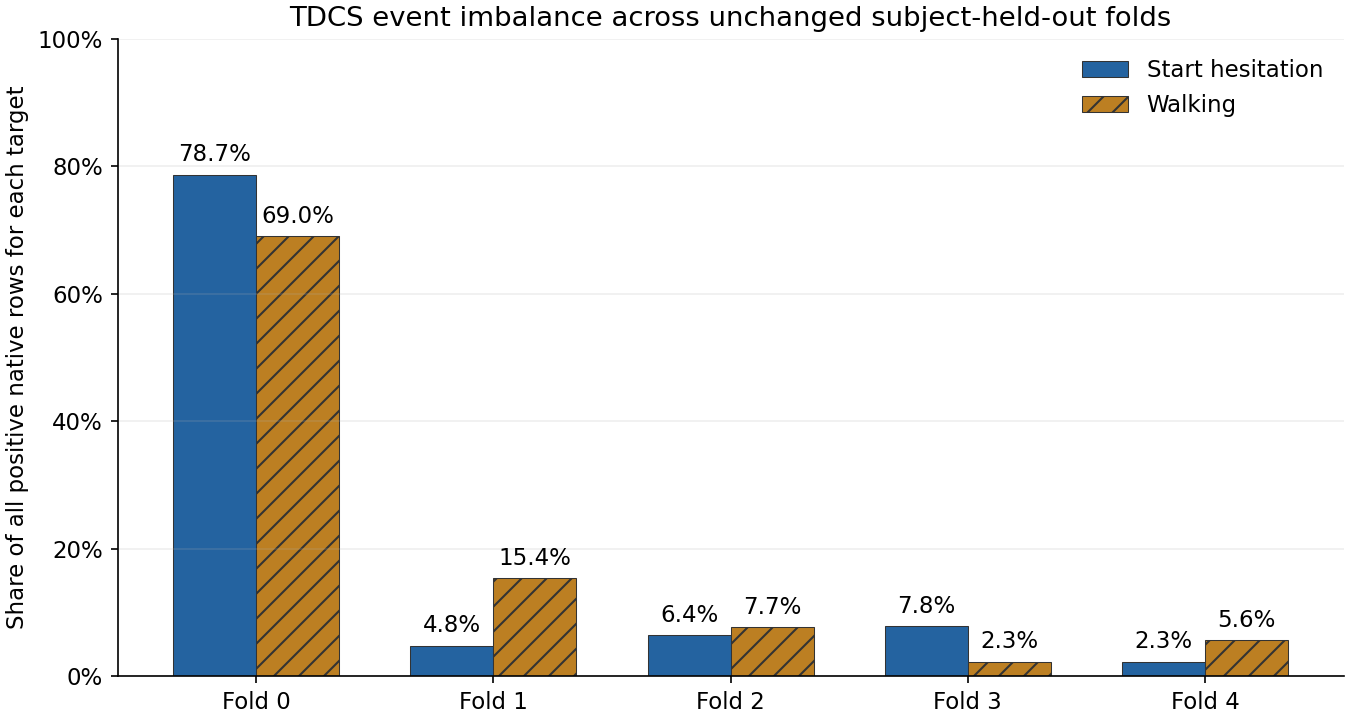

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(9, 4.8), layout='constrained')
shares = fold_counts / fold_counts.sum()
positions = np.arange(5)
for i, (target, label, color, hatch) in enumerate([
    ('StartHesitation', 'Start hesitation', '#2463a0', ''),
    ('Walking', 'Walking', '#bc7f22', '//'),
]):
    bars = ax.bar(positions + (i - 0.5) * 0.35, shares[target], 0.35, label=label,
                  color=color, hatch=hatch, edgecolor='#333333', linewidth=0.5)
    ax.bar_label(bars, labels=[f'{value:.1%}' for value in shares[target]], padding=4)
ax.set_xticks(positions, [f'Fold {fold}' for fold in range(5)])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylabel('Share of all positive native rows for each target')
ax.set_title('TDCS event imbalance across unchanged subject-held-out folds')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
balance_figure = WORK_ROOT / 'tdcs_frozen_fold_positive_balance.png'
fig.savefig(balance_figure, dpi=150)
plt.close(fig)
display(Image(filename=str(balance_figure)))

Fold 0 contains approximately 79% of hesitation-positive and 69% of
walking-positive rows. This makes some outer train/validation populations
very different. We leave the folds unchanged; this chart is not a reason
to report a resplit score as a like-for-like improvement.

## Results

### Train from scratch, or run the clearly labelled local wiring check

Full training saves per-epoch checkpoints, training-only subject receipts,
final EMA weights, native-row OOF scores, fold metrics, and candidate metrics
to `/kaggle/working/tdcs_two_target_neural/<fingerprint>`. Epoch checkpoints
allow same-configuration recovery if the output is mounted for a later run.

In [5]:
try:
    if RUN_FULL_TRAINING:
        result = trainer.run_experiment(output_root=WORK_ROOT)
    else:
        # Do not display synthetic AP as a measured TDCS result.
        with contextlib.redirect_stdout(io.StringIO()):
            result = trainer.smoke_experiment(output_root=WORK_ROOT / 'synthetic_wiring_only')
        assert result['smoke_only'] and not result['target_reached']
        print('Synthetic wiring completed: both architectures, five folds, native-row replay. NO TDCS mAP claim.')
    status = {'stage': 'complete', 'full_training': RUN_FULL_TRAINING, 'smoke_only': result['smoke_only']}
    (WORK_ROOT / 'startup_status.json').write_text(json.dumps(status, indent=2))
except BaseException as error:
    error_text = traceback.format_exc()
    (WORK_ROOT / 'python_error.txt').write_text(error_text)
    (WORK_ROOT / 'startup_status.json').write_text(json.dumps({'stage': 'error', 'type': type(error).__name__,
                                                              'message': str(error)}, indent=2))
    raise

Synthetic wiring completed: both architectures, five folds, native-row replay. NO TDCS mAP claim.


### Report actual two-target performance only after GPU training

In [6]:
if RUN_FULL_TRAINING:
    run_dir = Path(result['run_dir'])
    metrics = pd.read_csv(run_dir / 'candidate_metrics.csv')
    display(metrics.sort_values('two_target_mAP', ascending=False).style.format(
        {name: '{:.4f}' for name in [*trainer.TARGETS, 'two_target_mAP']}))
    print('Goal reached:', result['target_reached'])
    print('Each class AP:', result['class_average_precision'])
    print('Independent native-row AP recalculation is still required before promotion.')
else:
    print('GPU results pending. Preserved real two-target reference remains 0.1963; target remains 0.6.')

GPU results pending. Preserved real two-target reference remains 0.1963; target remains 0.6.


## Takeaways

A 0.6 result must be measured on the complete unchanged subject-held-out
population, not promised, inferred from training loss, or replaced with a
synthetic/window-only score. Promote a new model only after verifying its
saved OOF predictions against raw labels independently. If it misses 0.6,
retain the actual measurements and inspect the class/fold failures.

The old best models are preserved. This notebook makes no Kaggle competition
submission and performs no leaderboard scoring. Calibration is a later,
subject-disjoint validation step, not another name for sigmoid output.